In [ ]:
# FASE 1: IMPORTAR LIBRERÍAS Y CARGAR EL DATASET

import pandas as pd
import numpy as np
from google.colab import files

# Seleccionar y subir el archivo CSV desde el computador
archivo_subido = files.upload()

# Obtener el nombre del archivo cargado
nombre_archivo = next(iter(archivo_subido))

# Leer el dataset
df = pd.read_csv(nombre_archivo, encoding="utf-8-sig")

# Mostrar las primeras filas
print("Dataset cargado correctamente")
display(df.head())

Saving Dataset_ECNT_Social_Salud_2316_registros_simulados.csv to Dataset_ECNT_Social_Salud_2316_registros_simulados.csv
Dataset cargado correctamente


,codigo_municipio,departamento_dane,municipio_dane,anio,anio_indicadores_sociales,poblacion_total,poblacion_18_69,nbi_personas,miseria,componente_vivienda,...,nbi_disponible,casos_diabetes,prevalencia_diabetes_pct,casos_hipertension,prevalencia_hipertension_pct,casos_enfermedad_cardiovascular,prevalencia_cardiovascular_pct,estado_datos_salud,nota_poblacion,fuente_poblacion_salud
0,8001,ATLÁNTICO,BARRANQUILLA,2012,2018,875225,499950,0.09102,0.013991,0.014499,...,Sí,23342,4.669,75786,15.159,13047,2.610,SIMULADO - NO OFICIAL,"Población, casos y prevalencias simulados para...",Datos sintéticos generados con semilla fija; p...
1,8001,ATLÁNTICO,BARRANQUILLA,2013,2018,885728,548779,0.09102,0.013991,0.014499,...,Sí,26746,4.874,85798,15.634,15387,2.804,SIMULADO - NO OFICIAL,"Población, casos y prevalencias simulados para...",Datos sintéticos generados con semilla fija; p...
2,8001,ATLÁNTICO,BARRANQUILLA,2014,2018,896356,557220,0.09102,0.013991,0.014499,...,Sí,30857,5.538,86528,15.528,14422,2.588,SIMULADO - NO OFICIAL,"Población, casos y prevalencias simulados para...",Datos sintéticos generados con semilla fija; p...
3,8001,ATLÁNTICO,BARRANQUILLA,2015,2018,907113,570773,0.09102,0.013991,0.014499,...,Sí,28435,4.982,90376,15.834,15637,2.740,SIMULADO - NO OFICIAL,"Población, casos y prevalencias simulados para...",Datos sintéticos generados con semilla fija; p...
4,8001,ATLÁNTICO,BARRANQUILLA,2016,2018,917998,564916,0.09102,0.013991,0.014499,...,Sí,29010,5.135,90985,16.106,15558,2.754,SIMULADO - NO OFICIAL,"Población, casos y prevalencias simulados para...",Datos sintéticos generados con semilla fija; p...


In [ ]:
# FASE 2: EXPLORAR Y COMPRENDER LOS DATOS

# Cantidad de filas y columnas
print("Dimensiones del dataset:", df.shape)

# Nombres de las columnas
print("\nColumnas disponibles:")
print(df.columns.tolist())

# Tipos de datos y valores faltantes
print("\nInformación general:")
df.info()

# Cantidad de valores faltantes por columna
print("\nValores faltantes:")
display(df.isnull().sum().to_frame("Valores faltantes"))

# Revisar los años disponibles
print("\nPeriodo del dataset:")
print(df["anio"].min(), "-", df["anio"].max())

# Cantidad de municipios
print("\nMunicipios:", df["codigo_municipio"].nunique())

Dimensiones del dataset: (2316, 31)

Columnas disponibles:
['codigo_municipio', 'departamento_dane', 'municipio_dane', 'anio', 'anio_indicadores_sociales', 'poblacion_total', 'poblacion_18_69', 'nbi_personas', 'miseria', 'componente_vivienda', 'componente_agua_saneamiento', 'componente_hacinamiento', 'inasistencia_educativa', 'dependencia_economica', 'pct_viviendas_acueducto', 'pct_viviendas_alcantarillado', 'pct_saneamiento_inadecuado', 'pct_hogares_agua_cocina_acueducto', 'analfabetismo_15_mas', 'asistencia_escolar_5_14', 'poblacion_censada', 'nbi_disponible', 'casos_diabetes', 'prevalencia_diabetes_pct', 'casos_hipertension', 'prevalencia_hipertension_pct', 'casos_enfermedad_cardiovascular', 'prevalencia_cardiovascular_pct', 'estado_datos_salud', 'nota_poblacion', 'fuente_poblacion_salud']

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2316 entries, 0 to 2315
Data columns (total 31 columns):
 #   Column                             Non-Null Count  Dtype  
---

,Valores faltantes
codigo_municipio,0
departamento_dane,0
municipio_dane,0
anio,0
anio_indicadores_sociales,0
poblacion_total,0
poblacion_18_69,0
nbi_personas,0
miseria,0
componente_vivienda,0



Periodo del dataset:
2012 - 2023

Municipios: 193


In [ ]:
# FASE 3: ANALISIS EXPLORATORIO DE LOS DATOS

# 1. Estadísticas descriptivas de las variables numéricas
print("ESTADISTICAS DESCRIPTIVAS")
display(df.describe().T)

# 2. Revisar si existen registros duplicados
print("REGISTROS DUPLICADOS:", df.duplicated().sum())

# 3. Revisar cuántos registros hay por año
print("\nREGISTROS POR AÑO")
display(df["anio"].value_counts().sort_index())

# 4. Revisar los indicadores de salud simulados
columnas_salud = [
    "casos_diabetes",
    "prevalencia_diabetes_pct",
    "casos_hipertension",
    "prevalencia_hipertension_pct",
    "casos_enfermedad_cardiovascular",
    "prevalencia_cardiovascular_pct"
]

print("\nRESUMEN DE VARIABLES DE SALUD")
display(df[columnas_salud].describe().T)

# 5. Revisar el estado de los datos de salud
print("\nORIGEN DE LOS DATOS DE SALUD")
display(df["estado_datos_salud"].value_counts())

# 6. Revisar los valores faltantes en las columnas sociales
columnas_sociales_incompletas = [
    "pct_viviendas_acueducto",
    "pct_viviendas_alcantarillado",
    "pct_saneamiento_inadecuado",
    "pct_hogares_agua_cocina_acueducto",
    "analfabetismo_15_mas",
    "asistencia_escolar_5_14",
    "poblacion_censada"
]

print("\nVALORES DISPONIBLES EN INDICADORES SOCIALES")
display(df[columnas_sociales_incompletas].notna().sum().to_frame(
    "Valores disponibles"
))

ESTADISTICAS DESCRIPTIVAS


,count,mean,std,min,25%,50%,75%,max
codigo_municipio,2316.0,31249.274611,21275.675958,8001.000000,13620.000000,23162.000000,47258.000000,88564.000000
anio,2316.0,2017.500000,3.452798,2012.000000,2014.750000,2017.500000,2020.250000,2023.000000
anio_indicadores_sociales,2316.0,2018.000000,0.000000,2018.000000,2018.000000,2018.000000,2018.000000,2018.000000
poblacion_total,2316.0,79581.926598,93518.473560,5735.000000,34221.500000,71414.500000,100750.500000,997942.000000
poblacion_18_69,2316.0,49338.709413,57940.826692,3570.000000,21029.250000,43902.000000,62410.250000,635662.000000
nbi_personas,2316.0,0.359165,0.167431,0.080259,0.250465,0.317219,0.435323,0.934440
miseria,2316.0,0.123849,0.093609,0.006601,0.064267,0.095352,0.159451,0.612218
componente_vivienda,2316.0,0.195616,0.154701,0.006161,0.095343,0.141724,0.253643,0.713236
componente_agua_saneamiento,2316.0,0.108837,0.125496,0.004152,0.035741,0.071077,0.130403,0.905397
componente_hacinamiento,2316.0,0.084624,0.071743,0.007921,0.048952,0.067094,0.097227,0.609088


REGISTROS DUPLICADOS: 0

REGISTROS POR AÑO


,count
anio,
2012,193
2013,193
2014,193
2015,193
2016,193
2017,193
2018,193
2019,193
2020,193



RESUMEN DE VARIABLES DE SALUD


,count,mean,std,min,25%,50%,75%,max
casos_diabetes,2316.0,3580.301382,4014.925745,137.000,1602.75000,2945.0000,4574.25000,38326.000
prevalencia_diabetes_pct,2316.0,7.309592,1.341184,2.773,6.40750,7.3260,8.15075,11.525
casos_hipertension,2316.0,7271.418826,9468.246037,331.000,3101.50000,6032.0000,8626.75000,103862.000
prevalencia_hipertension_pct,2316.0,14.499183,2.453654,5.734,12.85800,14.3655,16.08350,21.622
casos_enfermedad_cardiovascular,2316.0,1247.302245,1558.318697,71.000,536.75000,1024.0000,1556.00000,19590.000
prevalencia_cardiovascular_pct,2316.0,2.541873,0.571883,1.102,2.16975,2.5295,2.88200,4.631



ORIGEN DE LOS DATOS DE SALUD


,count
estado_datos_salud,
SIMULADO - NO OFICIAL,2316



VALORES DISPONIBLES EN INDICADORES SOCIALES


,Valores disponibles
pct_viviendas_acueducto,300
pct_viviendas_alcantarillado,300
pct_saneamiento_inadecuado,300
pct_hogares_agua_cocina_acueducto,300
analfabetismo_15_mas,300
asistencia_escolar_5_14,300
poblacion_censada,300


In [ ]:
# FASE 4: LIMPIEZA Y PREPARACION DE LOS DATOS

# 1. Crear una copia del dataset original
df_limpio = df.copy()

# 2. Eliminar columnas con demasiados valores faltantes
columnas_eliminar = [
    "pct_viviendas_acueducto",
    "pct_viviendas_alcantarillado",
    "pct_saneamiento_inadecuado",
    "pct_hogares_agua_cocina_acueducto",
    "analfabetismo_15_mas",
    "asistencia_escolar_5_14",
    "poblacion_censada"
]

df_limpio = df_limpio.drop(columns=columnas_eliminar)

# 3. Eliminar columnas descriptivas que no se usarán como predictores
columnas_informativas = [
    "nota_poblacion",
    "fuente_poblacion_salud",
    "estado_datos_salud"
]

df_limpio = df_limpio.drop(columns=columnas_informativas)

# 4. Comprobar valores faltantes restantes
print("Dimensiones después de limpiar:", df_limpio.shape)

print("\nValores faltantes restantes:")
print(df_limpio.isnull().sum().sum())

# 5. Comprobar duplicados por municipio y año
duplicados = df_limpio.duplicated(
    subset=["codigo_municipio", "anio"]
).sum()

print("\nDuplicados por municipio y año:", duplicados)

# 6. Mostrar las primeras filas
display(df_limpio.head())

Dimensiones después de limpiar: (2316, 21)

Valores faltantes restantes:
0

Duplicados por municipio y año: 0


,codigo_municipio,departamento_dane,municipio_dane,anio,anio_indicadores_sociales,poblacion_total,poblacion_18_69,nbi_personas,miseria,componente_vivienda,...,componente_hacinamiento,inasistencia_educativa,dependencia_economica,nbi_disponible,casos_diabetes,prevalencia_diabetes_pct,casos_hipertension,prevalencia_hipertension_pct,casos_enfermedad_cardiovascular,prevalencia_cardiovascular_pct
0,8001,ATLÁNTICO,BARRANQUILLA,2012,2018,875225,499950,0.09102,0.013991,0.014499,...,0.038886,0.02949,0.020315,Sí,23342,4.669,75786,15.159,13047,2.610
1,8001,ATLÁNTICO,BARRANQUILLA,2013,2018,885728,548779,0.09102,0.013991,0.014499,...,0.038886,0.02949,0.020315,Sí,26746,4.874,85798,15.634,15387,2.804
2,8001,ATLÁNTICO,BARRANQUILLA,2014,2018,896356,557220,0.09102,0.013991,0.014499,...,0.038886,0.02949,0.020315,Sí,30857,5.538,86528,15.528,14422,2.588
3,8001,ATLÁNTICO,BARRANQUILLA,2015,2018,907113,570773,0.09102,0.013991,0.014499,...,0.038886,0.02949,0.020315,Sí,28435,4.982,90376,15.834,15637,2.740
4,8001,ATLÁNTICO,BARRANQUILLA,2016,2018,917998,564916,0.09102,0.013991,0.014499,...,0.038886,0.02949,0.020315,Sí,29010,5.135,90985,16.106,15558,2.754


In [ ]:
# FASE 5: SELECCIONAR VARIABLES PREDICTORAS Y OBJETIVO

# Variables sociales que utilizará el modelo
columnas_sociales = [
    "nbi_personas",
    "miseria",
    "componente_vivienda",
    "componente_agua_saneamiento",
    "componente_hacinamiento",
    "inasistencia_educativa",
    "dependencia_economica"
]

# Variables adicionales de contexto
columnas_contexto = [
    "poblacion_total",
    "poblacion_18_69",
    "anio"
]

# Variable que queremos predecir
variable_objetivo = "prevalencia_hipertension_pct"

# Construir los predictores y la salida
X = df_limpio[columnas_sociales + columnas_contexto].copy()
y = df_limpio[variable_objetivo].copy()

# Mostrar las dimensiones
print("Variables predictoras (X):", X.shape)
print("Variable objetivo (y):", y.shape)

print("\nColumnas predictoras:")
print(X.columns.tolist())

print("\nPrimeros valores de la variable objetivo:")
display(y.head())

print("\nResumen de la variable objetivo:")
display(y.describe())

Variables predictoras (X): (2316, 10)
Variable objetivo (y): (2316,)

Columnas predictoras:
['nbi_personas', 'miseria', 'componente_vivienda', 'componente_agua_saneamiento', 'componente_hacinamiento', 'inasistencia_educativa', 'dependencia_economica', 'poblacion_total', 'poblacion_18_69', 'anio']

Primeros valores de la variable objetivo:


,prevalencia_hipertension_pct
0,15.159
1,15.634
2,15.528
3,15.834
4,16.106



Resumen de la variable objetivo:


,prevalencia_hipertension_pct
count,2316.000000
mean,14.499183
std,2.453654
min,5.734000
25%,12.858000
50%,14.365500
75%,16.083500
max,21.622000


In [ ]:
# FASE 6: DIVIDIR LOS DATOS EN ENTRENAMIENTO, VALIDACION Y PRUEBA

from sklearn.model_selection import GroupShuffleSplit

# Identificar los municipios de cada registro
grupos = df_limpio["codigo_municipio"]

# Primera división: 70% entrenamiento y 30% temporal
divisor_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

idx_train, idx_temporal = next(
    divisor_1.split(X, y, groups=grupos)
)

X_train = X.iloc[idx_train].copy()
y_train = y.iloc[idx_train].copy()

X_temporal = X.iloc[idx_temporal].copy()
y_temporal = y.iloc[idx_temporal].copy()

# Segunda división: 15% validación y 15% prueba del total
grupos_temporales = grupos.iloc[idx_temporal]

divisor_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

idx_val_rel, idx_test_rel = next(
    divisor_2.split(
        X_temporal,
        y_temporal,
        groups=grupos_temporales
    )
)

X_val = X_temporal.iloc[idx_val_rel].copy()
y_val = y_temporal.iloc[idx_val_rel].copy()

X_test = X_temporal.iloc[idx_test_rel].copy()
y_test = y_temporal.iloc[idx_test_rel].copy()

# Mostrar tamaños de los conjuntos
print("ENTRENAMIENTO")
print("Registros:", len(X_train))
print("Municipios:", grupos.iloc[idx_train].nunique())

print("\nVALIDACION")
print("Registros:", len(X_val))
print("Municipios:", grupos.iloc[idx_temporal].iloc[idx_val_rel].nunique())

print("\nPRUEBA")
print("Registros:", len(X_test))
print("Municipios:", grupos.iloc[idx_temporal].iloc[idx_test_rel].nunique())

# Comprobar que no se repitan municipios entre conjuntos
municipios_train = set(grupos.iloc[idx_train])
municipios_val = set(grupos.iloc[idx_temporal].iloc[idx_val_rel])
municipios_test = set(grupos.iloc[idx_temporal].iloc[idx_test_rel])

print("\nMunicipios compartidos entre entrenamiento y validacion:",
      len(municipios_train & municipios_val))

print("Municipios compartidos entre entrenamiento y prueba:",
      len(municipios_train & municipios_test))

print("Municipios compartidos entre validacion y prueba:",
      len(municipios_val & municipios_test))

ENTRENAMIENTO
Registros: 1620
Municipios: 135

VALIDACION
Registros: 348
Municipios: 29

PRUEBA
Registros: 348
Municipios: 29

Municipios compartidos entre entrenamiento y validacion: 0
Municipios compartidos entre entrenamiento y prueba: 0
Municipios compartidos entre validacion y prueba: 0


In [ ]:
# FASE 7: SELECCION Y CONFIGURACION DE LOS MODELOS

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# MODELO 1: REGRESION MULTIPLE
modelo_regresion = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearRegression()
)

# MODELO 2: GRADIENT BOOSTING
modelo_gradient = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Comprobar que los modelos quedaron configurados
print("Modelos configurados correctamente.")
print("\nModelo 1: Regresion Multiple")
print(modelo_regresion)

print("\nModelo 2: Gradient Boosting")
print(modelo_gradient)

Modelos configurados correctamente.

Modelo 1: Regresion Multiple
Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler()),
                ('linearregression', LinearRegression())])

Modelo 2: Gradient Boosting
GradientBoostingRegressor(learning_rate=0.05, random_state=42)


In [ ]:
# FASE 8: ENTRENAMIENTO DE LOS MODELOS

# Entrenar el modelo de Regresión Múltiple
modelo_regresion.fit(X_train, y_train)

# Entrenar el modelo de Gradient Boosting
modelo_gradient.fit(X_train, y_train)

print("Entrenamiento finalizado correctamente.")

# Realizar predicciones con los datos de validación
pred_regresion_val = modelo_regresion.predict(X_val)
pred_gradient_val = modelo_gradient.predict(X_val)

# Mostrar algunas predicciones
print("\nPredicciones de Regresión Múltiple:")
print(pred_regresion_val[:10])

print("\nPredicciones de Gradient Boosting:")
print(pred_gradient_val[:10])

Entrenamiento finalizado correctamente.

Predicciones de Regresión Múltiple:
[14.02289293 14.120821   14.21414907 14.30180921 14.39924193 14.49299406
 14.58657499 14.67884459 14.77739153 14.87090853]

Predicciones de Gradient Boosting:
[14.92301552 14.88141678 14.76484386 14.79488962 14.91712766 14.90776225
 14.90776225 14.91507704 15.11608907 15.15757559]


In [ ]:
# FASE 9: EVALUACION CON LOS DATOS DE VALIDACION

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Calcular metricas para Regresion Multiple
mae_reg = mean_absolute_error(y_val, pred_regresion_val)
rmse_reg = np.sqrt(mean_squared_error(y_val, pred_regresion_val))
r2_reg = r2_score(y_val, pred_regresion_val)

# Calcular metricas para Gradient Boosting
mae_gb = mean_absolute_error(y_val, pred_gradient_val)
rmse_gb = np.sqrt(mean_squared_error(y_val, pred_gradient_val))
r2_gb = r2_score(y_val, pred_gradient_val)

# Mostrar resultados comparativos
resultados = pd.DataFrame({
    "Modelo": ["Regresion Multiple", "Gradient Boosting"],
    "MAE": [mae_reg, mae_gb],
    "RMSE": [rmse_reg, rmse_gb],
    "R2": [r2_reg, r2_gb]
})

display(resultados.round(4))

,Modelo,MAE,RMSE,R2
0,Regresion Multiple,2.1380,2.6357,0.0319
1,Gradient Boosting,2.1482,2.7201,-0.0311


In [ ]:
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Definir validación cruzada agrupada por municipio
cv = GroupKFold(n_splits=5)

# Configuraciones que vamos a probar
parametros = {
    "n_estimators": [100, 200],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_leaf": [5, 10]
}

# Crear búsqueda de mejores parámetros
busqueda = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=parametros,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

# Entrenar y ajustar usando solo los datos de entrenamiento
busqueda.fit(
    X_train,
    y_train,
    groups=df_limpio.loc[X_train.index, "codigo_municipio"]
)

# Mostrar la mejor configuración
print("Mejores parámetros:")
print(busqueda.best_params_)

print("\nMejor MAE en validación cruzada:")
print(round(-busqueda.best_score_, 4))

Mejores parámetros:
{'learning_rate': 0.03, 'max_depth': 2, 'min_samples_leaf': 5, 'n_estimators': 100}

Mejor MAE en validación cruzada:
1.9246


In [ ]:
# Obtener el mejor modelo encontrado
modelo_gradient_ajustado = busqueda.best_estimator_

# Predecir con los datos de validación
pred_gradient_ajustado = modelo_gradient_ajustado.predict(X_val)

# Calcular métricas
mae_ajustado = mean_absolute_error(y_val, pred_gradient_ajustado)
rmse_ajustado = np.sqrt(
    mean_squared_error(y_val, pred_gradient_ajustado)
)
r2_ajustado = r2_score(y_val, pred_gradient_ajustado)

# Comparar los modelos
resultados_ajuste = pd.DataFrame({
    "Modelo": [
        "Regresión Múltiple",
        "Gradient Boosting inicial",
        "Gradient Boosting ajustado"
    ],
    "MAE": [
        mae_reg,
        mae_gb,
        mae_ajustado
    ],
    "RMSE": [
        rmse_reg,
        rmse_gb,
        rmse_ajustado
    ],
    "R2": [
        r2_reg,
        r2_gb,
        r2_ajustado
    ]
})

display(resultados_ajuste.round(4))

,Modelo,MAE,RMSE,R2
0,Regresión Múltiple,2.1380,2.6357,0.0319
1,Gradient Boosting inicial,2.1482,2.7201,-0.0311
2,Gradient Boosting ajustado,2.1028,2.6426,0.0268


In [ ]:
# Seleccionar los dos modelos finalistas
modelos_finales = {
    "Regresión Múltiple": modelo_regresion,
    "Gradient Boosting ajustado": modelo_gradient_ajustado
}

resultados_test = []

for nombre, modelo in modelos_finales.items():

    # Predecir sobre el conjunto de prueba
    predicciones = modelo.predict(X_test)

    # Calcular métricas
    mae = mean_absolute_error(y_test, predicciones)
    rmse = np.sqrt(mean_squared_error(y_test, predicciones))
    r2 = r2_score(y_test, predicciones)

    resultados_test.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

tabla_test = pd.DataFrame(resultados_test)
display(tabla_test.round(4))

,Modelo,MAE,RMSE,R2
0,Regresión Múltiple,1.6955,2.0079,0.1674
1,Gradient Boosting ajustado,1.7538,2.1017,0.0878


In [ ]:
# Generar predicciones finales
predicciones_finales = modelo_regresion.predict(X_test)

# Crear tabla de comparación
comparacion = pd.DataFrame({
    "Prevalencia real (%)": y_test.values,
    "Prevalencia predicha (%)": predicciones_finales
})

comparacion["Error absoluto"] = abs(
    comparacion["Prevalencia real (%)"] -
    comparacion["Prevalencia predicha (%)"]
)

# Mostrar las primeras 15 observaciones
display(comparacion.head(15).round(4))

,Prevalencia real (%),Prevalencia predicha (%),Error absoluto
0,9.810,13.7060,3.8960
1,10.363,13.7824,3.4194
2,10.446,13.8912,3.4452
3,10.580,13.9554,3.3754
4,10.619,14.0965,3.4775
5,10.815,14.2005,3.3855
6,10.714,14.2763,3.5623
7,10.864,14.3653,3.5013
8,10.976,14.4977,3.5217
9,11.151,14.5586,3.4076


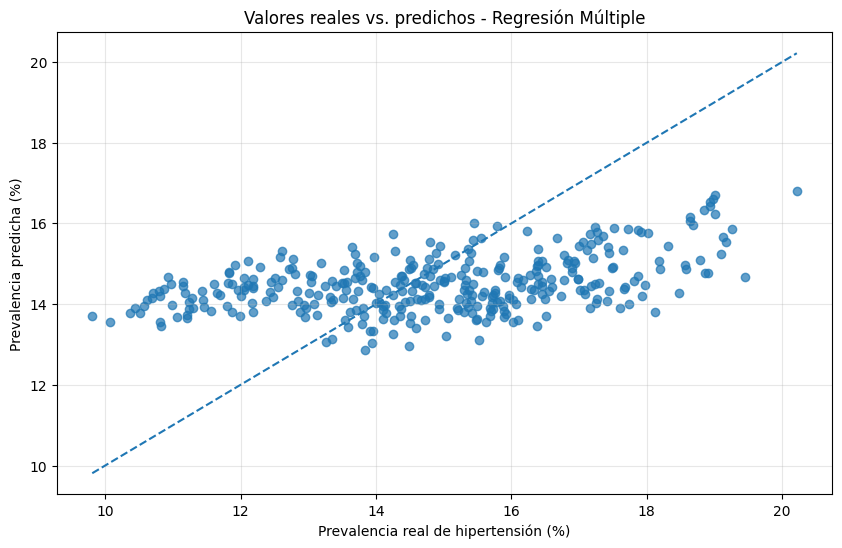

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    predicciones_finales,
    alpha=0.7
)

# Línea de predicción perfecta
limite_min = min(y_test.min(), predicciones_finales.min())
limite_max = max(y_test.max(), predicciones_finales.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.xlabel("Prevalencia real de hipertensión (%)")
plt.ylabel("Prevalencia predicha (%)")
plt.title("Valores reales vs. predichos - Regresión Múltiple")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Guardar la comparación final de los modelos
tabla_test.to_csv(
    "comparacion_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

# Descargar el archivo a tu computador
from google.colab import files
files.download("comparacion_modelos.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>